In [3]:

import re

# Step 1: Create documents
documents = {
    1: "The cat sat on the mat",
    2: "The dog barked at the cat",
    3: "The mat was blue and clean"
}

# Step 2: Define stopwords
stopwords = ["the", "was", "and", "on", "at"]

# Step 3: Preprocessing function
def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    words = text.split()

    words = [word for word in words if word not in stopwords]
    return words

# Step 4: Build inverted index
inverted_index = {}

for doc_id, content in documents.items():
    words = preprocess(content)

    for word in words:
        if word not in inverted_index:
            inverted_index[word] = []

        if doc_id not in inverted_index[word]:
            inverted_index[word].append(doc_id)

# Step 5: Display inverted index
print("Inverted Index:")
for word, doc_ids in inverted_index.items():
    print(word, ":", doc_ids)

# Step 6: Search document
query = input("\nEnter search word or sentence: ")

query_words = preprocess(query)

result = set()

for word in query_words:
    if word in inverted_index:
        result.update(inverted_index[word])

# Display results
if result:
    print("\nMatching Documents:")
    for doc_id in sorted(result):
        print("Document", doc_id, ":", documents[doc_id])
else:
    print("No matching documents found.")


Inverted Index:
cat : [1, 2]
sat : [1]
mat : [1, 3]
dog : [2]
barked : [2]
blue : [3]
clean : [3]



Enter search word or sentence:  cat



Matching Documents:
Document 1 : The cat sat on the mat
Document 2 : The dog barked at the cat


In [1]:
import re

docs = {
    1: "The cat sat on the mat",
    2: "The dog barked at the cat",
    3: "The mat was blue and clean"
}

stop = ["the", "was", "and", "on", "at"]
index = {}

def preprocess(text):
    words = re.sub(r'[^\w\s]', '', text.lower()).split()
    return [w for w in words if w not in stop]

for id, text in docs.items():
    for w in set(preprocess(text)):
        index.setdefault(w, []).append(id)

print("Inverted Index:", index)

query = preprocess(input("Enter query: "))
result = set()

for w in query:
    result.update(index.get(w, []))

for id in sorted(result):
    print("Document", id, ":", docs[id])

if not result:
    print("No matching documents")

Inverted Index: {'cat': [1, 2], 'mat': [1, 3], 'sat': [1], 'barked': [2], 'dog': [2], 'clean': [3], 'blue': [3]}


Enter query:  who barked on cat


Document 1 : The cat sat on the mat
Document 2 : The dog barked at the cat


PageRank Scores:
A : 0.3725
B : 0.1958
C : 0.3942
D : 0.0375


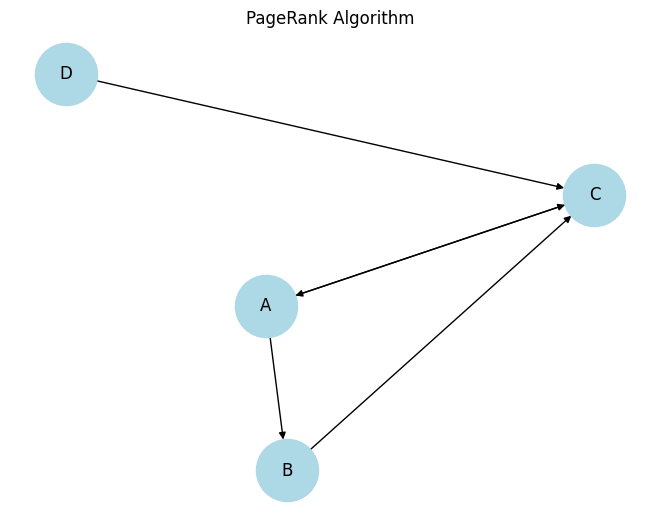

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

# Create directed graph
G = nx.DiGraph()

# Add links between pages
G.add_edges_from([
    ('A', 'B'),
    ('A', 'C'),
    ('B', 'C'),
    ('C', 'A'),
    ('D', 'C')
])

# Calculate PageRank
pagerank = nx.pagerank(G, alpha=0.85)

# Display PageRank scores
print("PageRank Scores:")
for page, score in sorted(pagerank.items()):
    print(page, ":", round(score, 4))

# Display graph
nx.draw(
    G,
    with_labels=True,
    node_color='lightblue',
    node_size=2000,
    arrows=True
)

plt.title("PageRank Algorithm")
plt.show()